# Digit Image Classification — Machine Learning Pipeline

**Non-tabular dataset:** 8×8 grayscale handwriting images. This notebook demonstrates data acquisition, preprocessing, image visualizations, model training, testing and evaluation.

In [2]:
import sys
from pathlib import Path

# Locate the project root
current_dir = Path.cwd()

if (current_dir / "src").is_dir():
    project_root = current_dir
elif (current_dir.parent / "src").is_dir():
    project_root = current_dir.parent
else:
    raise FileNotFoundError("Cannot locate the project's src folder.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay
from src.preprocessing import dataset, features, explain_features
from src.model import initial_train, MODEL_PATH, evaluate
import joblib

Project root: c:\Users\YES TECHNOLOGY\Documents\MNIST_Digit_MLOps


## 1. Acquire image data
We use scikit-learn handwritten digit **images**, not a tabular CSV. Each is 8×8 and labeled 0–9. Use an 80/20 stratified hold-out split.

Images: (1797, 8, 8) Labels: (1797,)
Training: (1437, 8, 8) Test: (360, 8, 8)


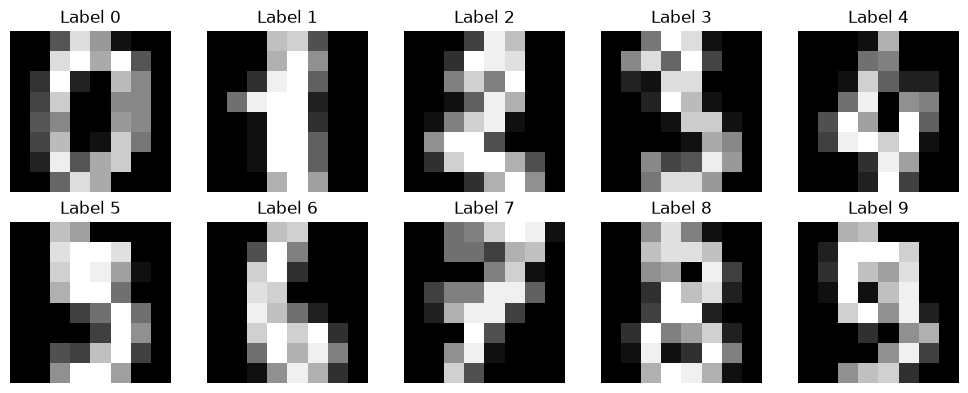

In [3]:
digits = load_digits()
print('Images:', digits.images.shape, 'Labels:', digits.target.shape)
X_train, X_test, y_train, y_test = dataset()
print('Training:', X_train.shape, 'Test:', X_test.shape)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for label, ax in enumerate(axes.ravel()):
    ix = np.where(digits.target == label)[0][0]
    ax.imshow(digits.images[ix], cmap='gray')
    ax.set_title(f'Label {label}')
    ax.axis('off')
plt.tight_layout(); plt.show()

## 2. Preprocess and inspect features
Pixel intensities are scaled from 0–16 to 0–1. Each 8×8 image is flattened to 64 neural-network inputs. Train/test indices are stratified and fixed (seed 42).

In [4]:
X_train_prepared = features(X_train)
X_test_prepared = features(X_test)
print('Shape:', X_train_prepared.shape, 'Range:', X_train_prepared.min(), X_train_prepared.max())
assert X_train_prepared.shape[1] == 64
assert 0 <= X_train_prepared.min() <= X_train_prepared.max() <= 1

Shape: (1437, 64) Range: 0.0 1.0


## 3. Visualize and interpret three image features
**Feature 1: stroke-occupied pixel count** approximates ink coverage. **Feature 2: average brightness** quantifies average ink intensity. **Feature 3: horizontal stroke center** quantifies where the strokes are concentrated horizontally. Compare distributions by class and write what the plotted differences tell you.

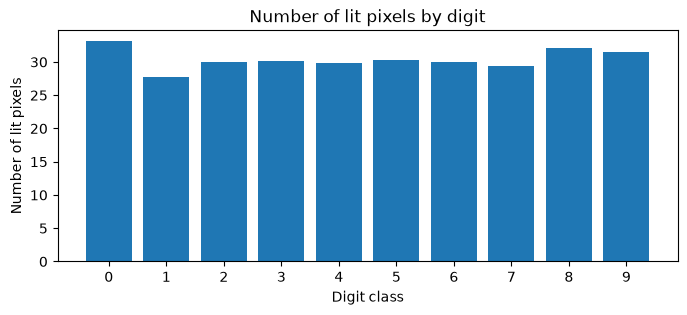

Number of lit pixels : min class 1 max class 0


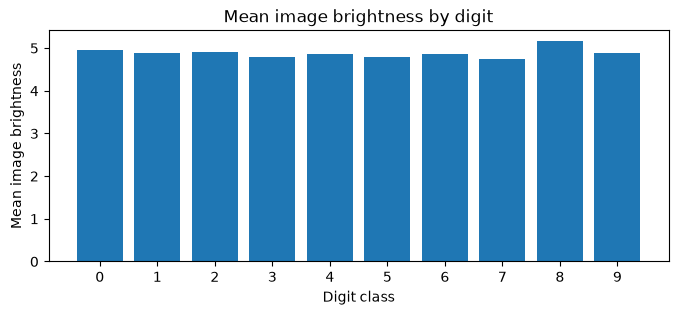

Mean image brightness : min class 7 max class 8


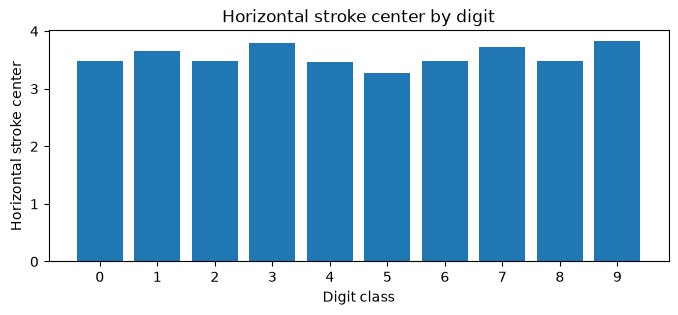

Horizontal stroke center : min class 5 max class 9


In [5]:
images = np.concatenate([X_train, X_test])
labels = np.concatenate([y_train, y_test])
occupied, brightness, center = explain_features(images)
features_to_plot = [(occupied, 'Number of lit pixels'), (brightness, 'Mean image brightness'), (center, 'Horizontal stroke center')]
for values, title in features_to_plot:
    group_means = [values[labels == digit].mean() for digit in range(10)]
    plt.figure(figsize=(8, 3))
    plt.bar(range(10), group_means)
    plt.xticks(range(10))
    plt.xlabel('Digit class')
    plt.ylabel(title)
    plt.title(title + ' by digit')
    plt.show()
    print(title, ': min class', np.argmin(group_means), 'max class', np.argmax(group_means))

## 4. Train a custom optimized model
MLP with 96/48 hidden units, Adam optimizer, **L2 regularization** (`alpha=0.001`) and **early stopping**. Train once offline and save the custom trained weights in `.pkl`. This file is reused for retraining.

In [6]:
training_metrics = initial_train()
print('Saved to:', MODEL_PATH)
training_metrics

Model saved: storage\models\digits_model.pkl Accuracy: 0.9611
Saved to: storage\models\digits_model.pkl


{'accuracy': 0.9611,
 'precision_macro': 0.9621,
 'recall_macro': 0.9606,
 'f1_macro': 0.9604,
 'log_loss': 0.1513,
 'confusion_matrix': [[35, 0, 0, 0, 1, 0, 0, 0, 0, 0],
  [0, 33, 0, 0, 0, 1, 0, 0, 1, 1],
  [0, 0, 35, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 37, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 36, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 37, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 35, 0, 1, 0],
  [0, 0, 0, 0, 0, 0, 0, 36, 0, 0],
  [0, 6, 0, 0, 0, 0, 0, 1, 28, 0],
  [0, 0, 0, 0, 0, 0, 0, 2, 0, 34]],
 'test_samples': 360,
 'model_version': 1,
 'retrained_images': 0}

## 5. Test predictions and report at least four metrics
Accuracy, macro precision, macro recall, macro F1 and log loss are computed on held-out test images; confusion matrix shows errors by class. The API `/metrics` reports the same held-out evaluation after retraining.

accuracy: 0.9611
precision_macro: 0.9621
recall_macro: 0.9606
f1_macro: 0.9604
log_loss: 0.1513


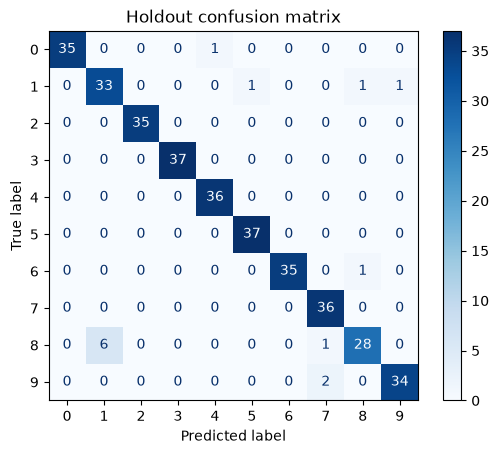

In [7]:
model = joblib.load(MODEL_PATH)
metrics = evaluate(model, X_test, y_test)
for key in ('accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'log_loss'):
    print(f'{key}: {metrics[key]}')
predictions = model.predict(features(X_test))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=range(10), cmap='Blues')
plt.title('Holdout confusion matrix'); plt.show()

## 6. Demonstrate one prediction

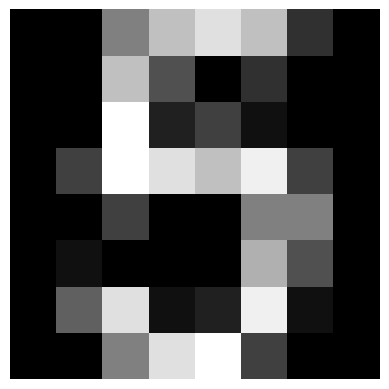

Correct label: 5 Predicted: 5


In [8]:
sample = 0
plt.imshow(X_test[sample], cmap='gray');plt.axis('off');plt.show()
print('Correct label:', y_test[sample], 'Predicted:', model.predict(features(X_test[sample][None]))[0])

## 7. Production evaluation and retraining
The running API supports single-image prediction, SQLite bulk labeled image uploads, a **retrain** button, model versioning and held-out evaluation. During retraining the app loads this saved model (`joblib.load`), sets `warm_start=True`, trains on original and new labeled images, saves it again and calculates updated test metrics. Inspect `src/api.py` for full pipeline. Use the UI to demonstrate the trigger.